# Experiment 01: Data overview

Card: [exp01_overview.md](../../experiments/exp01_overview.md)

In [ ]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import METERS
from src.raw_data import read_building, read_readings, read_weather

SMOKE = os.environ.get("SMOKE") == "1"
if SMOKE:
    N_READINGS = 200_000  # training rows kept after loading
    N_HIST, N_KDE, N_JOIN, N_HEXBIN = 20_000, 2_000, 30_000, 1_000
    FIGURE = FIGURE_MISSING = FIGURE_TARGET = FIGURE_TEMPERATURE = None
else:
    N_READINGS = None  # all 20.2M
    N_HIST, N_KDE, N_JOIN, N_HEXBIN = 2_000_000, 300_000, 3_000_000, 100_000  # rows sampled per plot
    FIGURE = "../../figures/exp01_overview.png"
    FIGURE_MISSING = "../../figures/exp01_overview_missing.png"
    FIGURE_TARGET = "../../figures/exp01_overview_target.png"
    FIGURE_TEMPERATURE = "../../figures/exp01_overview_temperature.png"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

In [ ]:
building, train, weather = read_building(), read_readings("train.csv"), read_weather("weather_train.csv")
if N_READINGS:
    train = train.sample(N_READINGS, random_state=0)

for name, df in [("building", building), ("train", train), ("weather", weather)]:
    print(
        f"{name:9s} shape={df.shape}  memory={df.memory_usage(deep=True).sum() / 2**20:,.1f} MB"
    )

building  shape=(1449, 6)  memory=0.0 MB
train     shape=(20216100, 4)  memory=289.2 MB
weather   shape=(139773, 9)  memory=4.9 MB


## Data overview

In [ ]:
display(building.head())
display(train.head())
display(weather.head())

,site_id,building_id,primary_use,square_feet,year_built,floor_count
0,0,0,Education,7432,"2,008.000",NaN
1,0,1,Education,2720,"2,004.000",NaN
2,0,2,Education,5376,"1,991.000",NaN
3,0,3,Education,23685,"2,002.000",NaN
4,0,4,Education,116607,"1,975.000",NaN


,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01,0.000
1,1,0,2016-01-01,0.000
2,2,0,2016-01-01,0.000
3,3,0,2016-01-01,0.000
4,4,0,2016-01-01,0.000


,site_id,timestamp,air_temperature,cloud_coverage,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed
0,0,2016-01-01 00:00:00,25.000,6.000,20.000,NaN,"1,019.700",0.000,0.000
1,0,2016-01-01 01:00:00,24.400,NaN,21.100,-1.000,"1,020.200",70.000,1.500
2,0,2016-01-01 02:00:00,22.800,2.000,21.100,0.000,"1,020.200",0.000,0.000
3,0,2016-01-01 03:00:00,21.100,2.000,20.600,0.000,"1,020.100",0.000,0.000
4,0,2016-01-01 04:00:00,20.000,2.000,20.000,-1.000,"1,020.000",250.000,2.600


In [ ]:
print("train timestamps :", train.timestamp.min(), "->", train.timestamp.max())
print("weather timestamps:", weather.timestamp.min(), "->", weather.timestamp.max())
print()
print(
    "buildings in metadata:",
    building.building_id.nunique(),
    "| in train:",
    train.building_id.nunique(),
)
print(
    "sites in metadata    :",
    building.site_id.nunique(),
    "| in weather:",
    weather.site_id.nunique(),
)
print(
    "building_id range    :",
    building.building_id.min(),
    "-",
    building.building_id.max(),
)
print()
print(
    "Meter series (building x meter) in train:",
    train.groupby(["building_id", "meter"]).ngroups,
)
print(train.meter.map(METERS).value_counts().rename("rows per meter"))

train timestamps : 2016-01-01 00:00:00 -> 2016-12-31 23:00:00
weather timestamps: 2016-01-01 00:00:00 -> 2016-12-31 23:00:00

buildings in metadata: 1449 | in train: 1449
sites in metadata    : 16 | in weather: 16
building_id range    : 0 - 1448



Meter series (building x meter) in train: 2380


meter
electricity     12060910
chilledwater     4182440
steam            2708713
hotwater         1264037
Name: rows per meter, dtype: int64


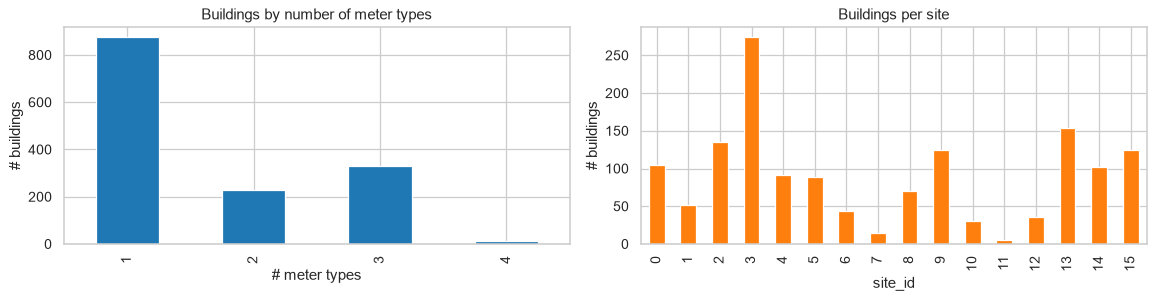

In [ ]:
meters_per_building = (
    train.groupby("building_id").meter.nunique().value_counts().sort_index()
)
buildings_per_site = building.groupby("site_id").building_id.count()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
meters_per_building.plot.bar(ax=axes[0], color="tab:blue")
axes[0].set(
    title="Buildings by number of meter types",
    xlabel="# meter types",
    ylabel="# buildings",
)
buildings_per_site.plot.bar(ax=axes[1], color="tab:orange")
axes[1].set(title="Buildings per site", xlabel="site_id", ylabel="# buildings")
plt.tight_layout()

## Data quality

In [ ]:
def missing_report(df):
    miss = df.isna().mean().mul(100).rename("% missing")
    return miss[miss > 0].sort_values(ascending=False).to_frame()


print("building_metadata")
display(missing_report(building))
print("train")
display(missing_report(train))
print("weather_train")
display(missing_report(weather))

building_metadata


,% missing
floor_count,75.500
year_built,53.416


train


,% missing


weather_train


,% missing
cloud_coverage,49.490
precip_depth_1_hr,35.979
sea_level_pressure,7.597
wind_direction,4.484
wind_speed,0.217
dew_temperature,0.081
air_temperature,0.039


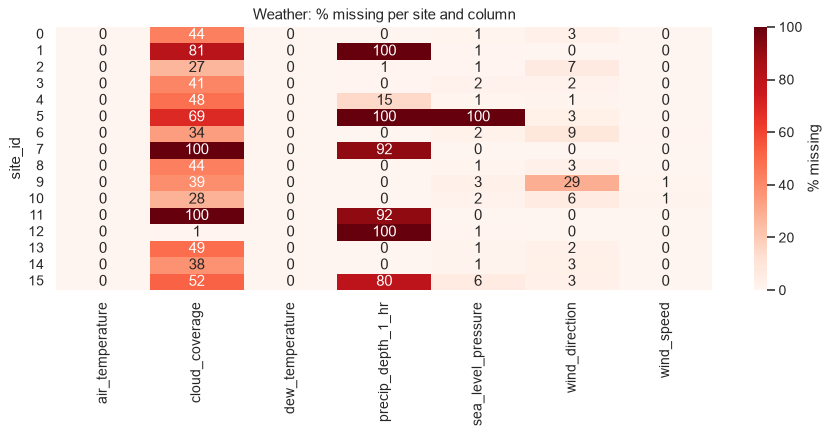

In [ ]:
weather_missing_by_site = (
    weather.drop(columns="timestamp")
    .groupby("site_id")
    .agg(lambda s: s.isna().mean() * 100)
)
fig = plt.figure(figsize=(10, 5))
sns.heatmap(
    weather_missing_by_site,
    annot=True,
    fmt=".0f",
    cmap="Reds",
    cbar_kws={"label": "% missing"},
)
plt.yticks(rotation=0)
plt.title("Weather: % missing per site and column")
plt.tight_layout()
if FIGURE_MISSING:
    fig.savefig(FIGURE_MISSING, dpi=150, bbox_inches="tight")

In [ ]:
print("duplicate building rows      :", building.building_id.duplicated().sum())
print(
    "duplicate train keys         :",
    train.duplicated(["building_id", "meter", "timestamp"]).sum(),
)
print(
    "duplicate weather keys       :", weather.duplicated(["site_id", "timestamp"]).sum()
)

HOURS_2016 = 366 * 24  # leap year
weather_hours = (
    weather.groupby("site_id").timestamp.nunique().rename("hours present").to_frame()
)
weather_hours["hours missing"] = HOURS_2016 - weather_hours["hours present"]
display(weather_hours.T)

duplicate building rows      : 0


duplicate train keys         : 0
duplicate weather keys       : 0


site_id,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
hours present,8784,8763,8783,8780,8783,8755,8782,8614,8784,8780,8782,8614,8755,8783,8777,8454
hours missing,0,21,1,4,1,29,2,170,0,4,2,170,29,1,7,330


## Building metadata

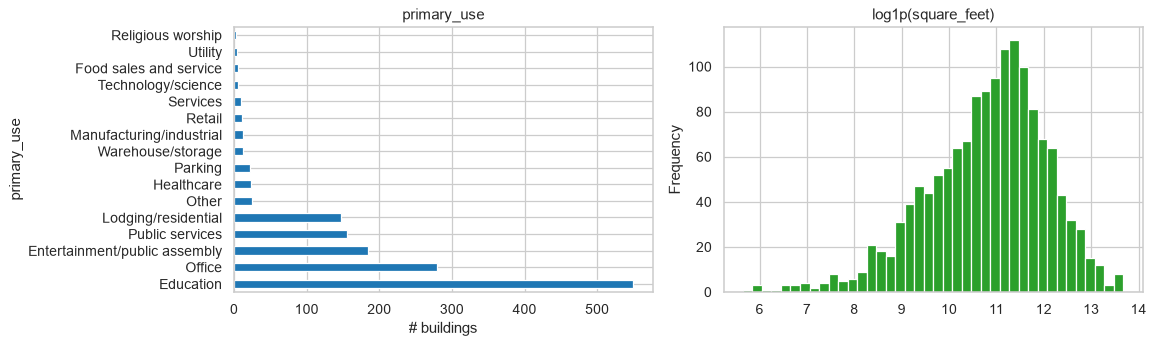

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
building.primary_use.value_counts().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set(title="primary_use", xlabel="# buildings")
np.log1p(building.square_feet).plot.hist(bins=40, ax=axes[1], color="tab:green")
axes[1].set(title="log1p(square_feet)")
plt.tight_layout()

In [ ]:
# Is missingness site-dependent? (informative missingness / different data sources)
meta_missing = (
    building.groupby("site_id")[["year_built", "floor_count"]]
    .agg(lambda s: s.isna().mean() * 100)
    .round(0)
)
display(meta_missing.T)

site_id,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
year_built,0.000,22.000,30.000,52.000,2.000,1.000,100.000,7.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,9.000
floor_count,100.000,0.000,100.000,100.000,0.000,0.000,100.000,0.000,0.000,100.000,0.000,100.000,75.000,100.000,100.000,100.000


## Target

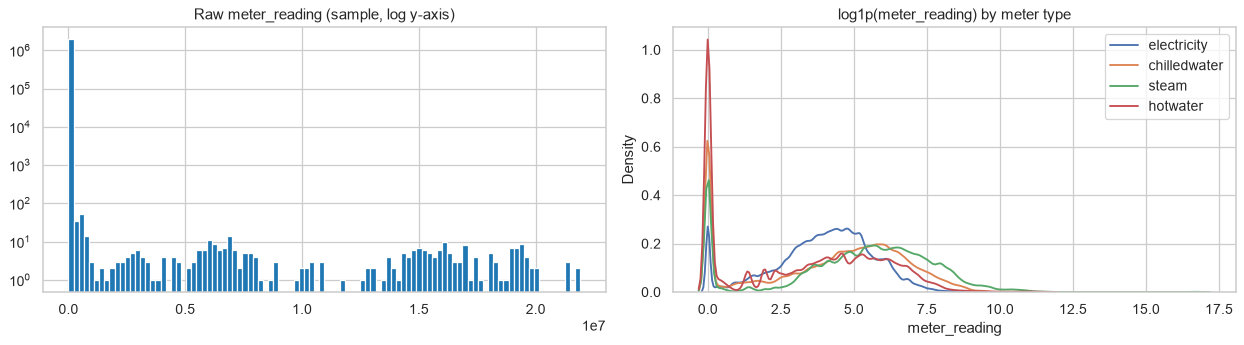

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(
    train.meter_reading.sample(N_HIST, random_state=0),
    bins=100,
    log=True,
    color="tab:blue",
)
axes[0].set(title="Raw meter_reading (sample, log y-axis)")
for m, name in METERS.items():
    sns.kdeplot(
        np.log1p(
            train.loc[train.meter == m, "meter_reading"].sample(N_KDE, random_state=0)
        ),
        ax=axes[1],
        label=name,
        bw_adjust=0.5,
    )
axes[1].set(title="log1p(meter_reading) by meter type")
axes[1].legend()
plt.tight_layout()
if FIGURE_TARGET:
    fig.savefig(FIGURE_TARGET, dpi=150, bbox_inches="tight")

In [ ]:
zero_share = (
    (train.meter_reading == 0).groupby(train.meter.map(METERS)).mean().mul(100)
)
print("% zero readings per meter type:")
print(zero_share.round(1).to_string())

% zero readings per meter type:
meter
chilledwater   15.700
electricity     4.400
hotwater       26.900
steam          12.800


In [ ]:
series_total = train.groupby(["building_id", "meter"]).meter_reading.sum()
building_id, meter = series_total.idxmax()
print(
    f"Largest series: building {building_id}, {METERS[meter]} — "
    f"{series_total.max() / series_total.sum():.1%} of all energy in train"
)

Largest series: building 1099, steam — 78.3% of all energy in train


## Features vs target

In [ ]:
# Join on a sample to keep memory reasonable
sample = (
    train.sample(N_JOIN, random_state=0)
    .merge(building, on="building_id", how="left")
    .merge(weather, on=["site_id", "timestamp"], how="left")
)
sample["log_reading"] = np.log1p(sample.meter_reading)
sample["meter_name"] = sample.meter.map(METERS)
print("rows without matching weather:", f"{sample.air_temperature.isna().mean():.1%}")

rows without matching weather: 0.5%


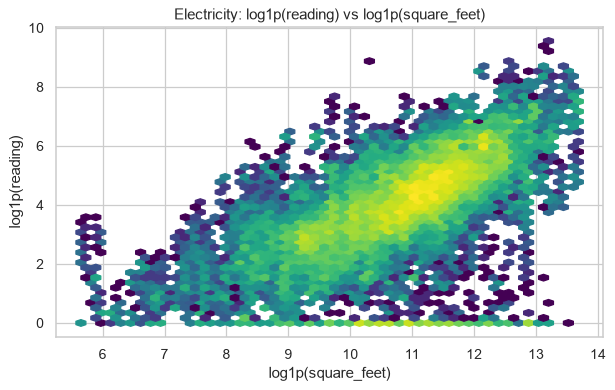

In [ ]:
sub = sample[sample.meter == 0].sample(N_HEXBIN, random_state=0)
plt.figure(figsize=(7, 4.5))
plt.hexbin(np.log1p(sub.square_feet), sub.log_reading, gridsize=50, bins="log", cmap="viridis")
plt.title("Electricity: log1p(reading) vs log1p(square_feet)")
plt.xlabel("log1p(square_feet)")
plt.ylabel("log1p(reading)")
plt.tight_layout()

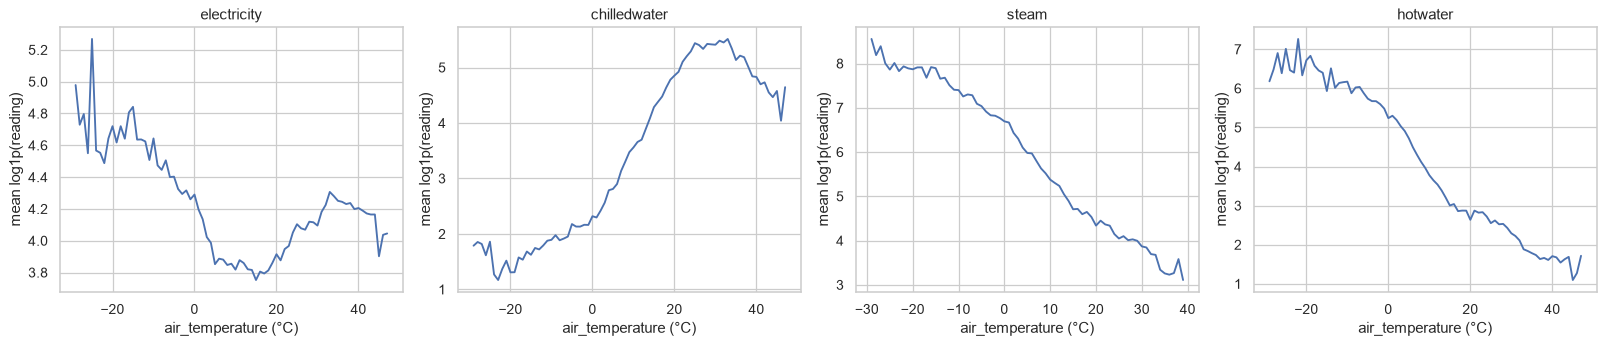

In [ ]:
# Weather response differs by meter type: cooling vs heating load
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
for ax, (m, name) in zip(axes, METERS.items()):
    s = sample[(sample.meter == m) & sample.air_temperature.notna()]
    s.groupby(s.air_temperature.round()).log_reading.mean().plot(ax=ax)
    ax.set(title=name, xlabel="air_temperature (°C)", ylabel="mean log1p(reading)")
plt.tight_layout()
if FIGURE_TEMPERATURE:
    fig.savefig(FIGURE_TEMPERATURE, dpi=150, bbox_inches="tight")

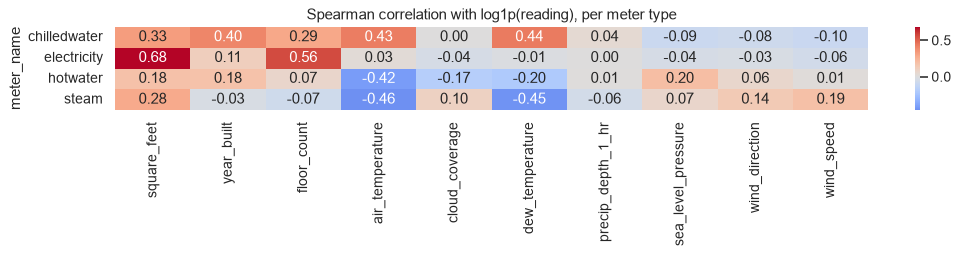

In [ ]:
num_cols = [
    "log_reading",
    "square_feet",
    "year_built",
    "floor_count",
    "air_temperature",
    "cloud_coverage",
    "dew_temperature",
    "precip_depth_1_hr",
    "sea_level_pressure",
    "wind_direction",
    "wind_speed",
]
corr = (
    sample.assign(square_feet=np.log1p(sample.square_feet))
    .groupby("meter_name")[num_cols]
    .corr(method="spearman")
    .xs("log_reading", level=1)[num_cols[1:]]
)
fig = plt.figure(figsize=(12, 3))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation with log1p(reading), per meter type")
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")